In [4]:
spot = 90
strike = 100
print (spot - strike)

-10


In [5]:
print (max(spot - strike, 0))

0


In [6]:
def call_payoff (S, K) :
    return max (S - K, 0)

In [8]:
print (call_payoff(110, 100))
print (call_payoff(90, 100))

10
0


In [9]:
def put_payoff (S, K) :
    return max (K - S, 0)

In [12]:
print (put_payoff (110, 100))
print (put_payoff (90, 100))

0
10


In [21]:
def long_call_profit(S, K, premium) :
    return call_payoff(S, K) - premium


In [22]:
print (long_call_profit(90, 100, 3))
print (long_call_profit(110, 100, 3))

-3
7


In [33]:
def long_put_profit(S, K, premium) :
    return put_payoff(S, K) - premium

In [35]:
print (long_put_profit(90, 100, 3))
print (long_put_profit(110,100, 3))

7
-3


In [36]:
import numpy as np
import matplotlib.pyplot as plt

In [38]:
S = np.linspace(60, 140, 9)
print(S)

[ 60.  70.  80.  90. 100. 110. 120. 130. 140.]


In [42]:
def call_payoff(S, K) :
    return np.maximum (S - K, 0)

In [43]:
def put_payoff (S, K) :
    return np.maximum (K - S, 0)

In [45]:
print(call_payoff(S, 100))
print(put_payoff(S, 100))

[ 0.  0.  0.  0.  0. 10. 20. 30. 40.]
[40. 30. 20. 10.  0.  0.  0.  0.  0.]


In [46]:
S = np.linspace(60, 140, 500)

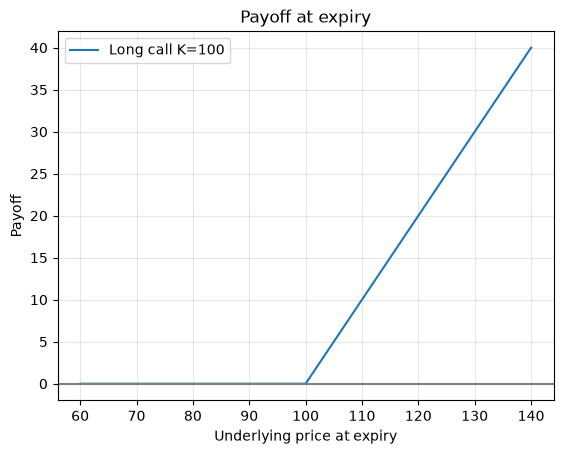

In [48]:
plt.plot(S, call_payoff(S, 100), label="Long call K=100") # la linea: x = prezzi, y= payoff
plt.axhline(0, color="grey") # horizontal line at zero
plt.xlabel("Underlying price at expiry") #x-axis label
plt.ylabel("Payoff") #y-axis label
plt.title("Payoff at expiry") #chart title
plt.legend() #show the legend (uses label)
plt.grid(alpha=0.3) #light grid
plt.show() #draw the chart

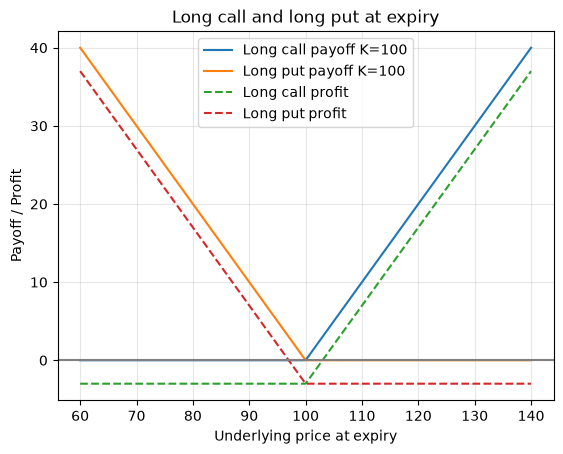

In [50]:
S = np.linspace(60, 140, 500)

plt.plot(S, call_payoff(S, 100), label="Long call payoff K=100")
plt.plot(S, put_payoff(S, 100), label="Long put payoff K=100")
plt.plot(S, long_call_profit(S, 100, 3), "--", label="Long call profit")
plt.plot(S, long_put_profit(S, 100, 3), "--", label="Long put profit")
plt.axhline(0, color="grey")
plt.xlabel("Underlying price at expiry")
plt.ylabel("Payoff / Profit")
plt.title("Long call and long put at expiry")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [51]:
leg = {"type": "call", "K": 100, "qty": 1, "premium": 3}
print(leg["K"])
print(leg["type"])

100
call


In [52]:
straddle = [
    {"type": "call", "K": 100, "qty": 1, "premium": 3},
    {"type": "put",  "K": 100, "qty": 1, "premium": 3},
]
print(len(straddle))
print(straddle[0]["type"])

2
call


In [53]:
for leg in straddle:
    if leg["type"] == "call":
        print("this is a call")
    else:
        print("this is a put")

this is a call
this is a put


In [54]:
def strategy_profit(S, legs):
    total = 0                                   # start from zero
    for leg in legs:                            # for each leg...
        if leg["type"] == "call":
            payoff = call_payoff(S, leg["K"])
        else:
            payoff = put_payoff(S, leg["K"])
        total = total + leg["qty"] * (payoff - leg["premium"])   # add this leg's profit
    return total                                # after the loop, return the sum

In [56]:
print(strategy_profit(90, straddle))
print(strategy_profit(100, straddle))
print(strategy_profit(110, straddle))

4
-6
4


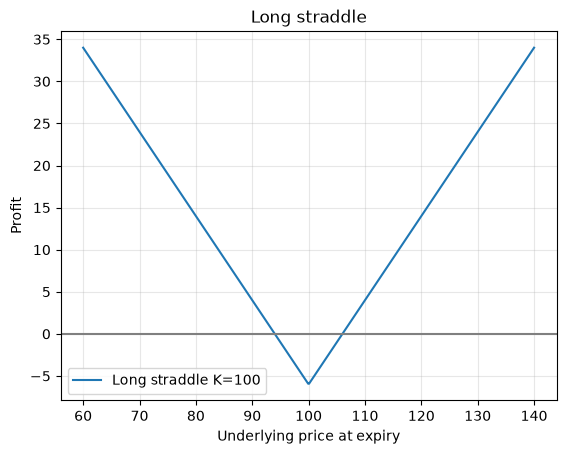

In [57]:
S = np.linspace(60, 140, 500)

plt.plot(S, strategy_profit(S, straddle), label="Long straddle K=100")
plt.axhline(0, color="grey")
plt.xlabel("Underlying price at expiry")
plt.ylabel("Profit")
plt.title("Long straddle")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

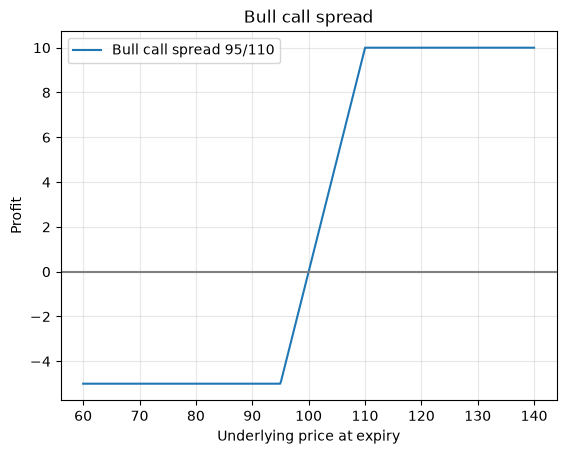

In [58]:
bull_call_spread = [
    {"type": "call", "K": 95,  "qty": 1,  "premium": 7},   # buy the 95 call
    {"type": "call", "K": 110, "qty": -1, "premium": 2},   # sell the 110 call
]

plt.plot(S, strategy_profit(S, bull_call_spread), label="Bull call spread 95/110")
plt.axhline(0, color="grey")
plt.xlabel("Underlying price at expiry")
plt.ylabel("Profit")
plt.title("Bull call spread")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [59]:
profit = strategy_profit(S, bull_call_spread)

print("Max profit:", profit.max())
print("Max loss:", profit.min())

# break-even: where the profit changes sign
sign_changes = np.where(np.diff(np.sign(profit)) != 0)[0]
print("Break-even:", S[sign_changes])

Max profit: 10.0
Max loss: -5.0
Break-even: [99.91983968]
